# Dropout prediction — Step 4: Evaluating the models

All training happens in **`src/model.py`**. This notebook only **reads its predictions and measures them**.
So changing a threshold here re-scores in a second without retraining anything.

**Run this first** (from the project root):
```
python src/model.py
```

### How the predictions were made

- **5-fold stratified cross-validation, repeated 5 times** with different shuffles → 25 test folds.
- Every student is predicted by a model that **never saw them** during training.
- Each metric is reported as **mean ± std across the 25 folds**, so we can see how much it moves around
  (with only 125 dropouts, one lucky split can easily add or lose 0.1 F1).

### The experiments

| Name | What it is |
|---|---|
| `majority` | Always says "stays". The floor. |
| `one_rule` | One cut-off on `mean_score` learned per fold (a decision stump). The rule a tutor could apply by hand. |
| `logreg` | Logistic regression on the **day-14** features. **Our main model.** |
| `gboost` | Gradient boosting, same features. Is a more complex model worth it? |
| `logreg_no_country` | `logreg` without `country`. Fairness check. |
| `logreg_leaky` | Whole-course features **plus `refund_requested`**. Shows what the leak looks like. |

## 0. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             roc_auc_score, average_precision_score,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import model as m   # our modelling code, for its settings and feature lists

MODELS = ROOT / "data" / "models"
oof = pd.read_csv(MODELS / "oof_predictions.csv")
coefs = pd.read_csv(MODELS / "logreg_coefficients.csv")

print(f"{m.N_REPEATS} repeats x {m.N_SPLITS} folds | experiments: {list(oof['experiment'].unique())}")
oof.head()

5 repeats x 5 folds | experiments: ['majority', 'one_rule', 'logreg', 'gboost', 'logreg_no_country', 'logreg_leaky']


,experiment,repeat,fold,student_id,y_true,proba
0,majority,0,0,S002,0,0.25
1,majority,0,0,S003,0,0.25
2,majority,0,0,S005,0,0.25
3,majority,0,0,S013,0,0.25
4,majority,0,0,S016,0,0.25


## 1. Which metric matters?

A dropout model makes two kinds of mistakes:

| Mistake | What happens | Cost |
|---|---|---|
| **Miss** an at-risk student (false negative) | Nobody reaches out; they quit | A lost customer |
| **False alarm** (false positive) | A student who'd have stayed gets a nudge | One extra email / tutor check-in |

A miss costs much more than a false alarm, so **recall** (the share of real dropouts we catch) matters most.

But recall can't be the *only* goal. Flag everyone and recall is 100%, but the tutor team drowns.
So we watch **precision** (of the students we flag, how many really are at risk) and **how many students get flagged**.

**Accuracy is misleading here.** 75% of students stay, so "always predict stays" already scores 75% accuracy while catching nobody.

## 2. Scoring helpers

In [2]:
def fold_scores(group, threshold):
    """All metrics for one test fold."""
    y, p = group["y_true"], group["proba"]
    pred = (p >= threshold).astype(int)
    return pd.Series({
        "recall":    recall_score(y, pred, zero_division=0),
        "precision": precision_score(y, pred, zero_division=0),
        "f1":        f1_score(y, pred, zero_division=0),
        "accuracy":  accuracy_score(y, pred),
        "roc_auc":   roc_auc_score(y, p) if p.nunique() > 1 else 0.5,
        "pr_auc":    average_precision_score(y, p),
        "flagged_%": pred.mean() * 100,
    })


def per_fold(oof, threshold=0.5):
    return (oof.groupby(["experiment", "repeat", "fold"])[["y_true", "proba"]]
               .apply(fold_scores, threshold=threshold)
               .reset_index())


def summary(oof, threshold=0.5):
    """Mean ± std across all test folds, one row per experiment."""
    folds = per_fold(oof, threshold)
    metrics = ["recall", "precision", "f1", "accuracy", "roc_auc", "pr_auc", "flagged_%"]
    agg = folds.groupby("experiment")[metrics].agg(["mean", "std"])
    table = pd.DataFrame({
        k: agg[k]["mean"].map("{:.2f}".format) + " ± " + agg[k]["std"].map("{:.2f}".format) for k in metrics
    })
    return table.reindex([e for e in m.EXPERIMENTS if e in table.index])   # same order as model.py

- **ROC-AUC / PR-AUC** measure ranking quality and don't depend on the threshold. ROC-AUC: 0.5 = coin flip, 1 = perfect.
  PR-AUC: the base rate (0.25) = coin flip.
- **Recall, precision, F1, accuracy, flagged %** all depend on the cut-off we pick.

## 3. All models at the default threshold (0.5)

In [3]:
summary(oof, threshold=0.5)

,recall,precision,f1,accuracy,roc_auc,pr_auc,flagged_%
experiment,,,,,,,
majority,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,0.75 ± 0.00,0.50 ± 0.00,0.25 ± 0.00,0.00 ± 0.00
one_rule,0.63 ± 0.14,0.38 ± 0.06,0.47 ± 0.06,0.64 ± 0.07,0.64 ± 0.05,0.33 ± 0.04,41.84 ± 11.57
logreg,0.66 ± 0.09,0.45 ± 0.05,0.53 ± 0.06,0.71 ± 0.04,0.76 ± 0.06,0.60 ± 0.07,37.12 ± 4.36
gboost,0.34 ± 0.10,0.64 ± 0.13,0.44 ± 0.10,0.79 ± 0.04,0.75 ± 0.06,0.57 ± 0.08,13.48 ± 2.90
logreg_no_country,0.67 ± 0.10,0.45 ± 0.06,0.54 ± 0.07,0.71 ± 0.04,0.77 ± 0.06,0.61 ± 0.07,36.96 ± 3.75
logreg_leaky,0.91 ± 0.05,0.87 ± 0.06,0.89 ± 0.04,0.94 ± 0.02,0.99 ± 0.01,0.96 ± 0.02,26.12 ± 2.32


**Reading the table:**

- `majority` gets 75% accuracy and **0 recall**, which shows why accuracy is the wrong metric.
- `one_rule` (just a cut-off on score) already catches about 6 in 10 dropouts. Any model has to beat that.
- `logreg` matches one_rule's recall with better precision, and clearly better ranking (ROC-AUC ~0.75 vs ~0.64).
- `gboost` ranks about as well as logreg but, at 0.5, it catches only about a third of dropouts. It wasn't trained with class
  weights, so its probabilities sit lower. Comparing at a fixed 0.5 is unfair to it, so Section 6 compares by curve instead.
- `logreg_leaky` looks amazing (~0.98 AUC). See the next section.

## 4. The leak, in one chart

Same algorithm, different inputs: day-14 features vs. whole-course features + `refund_requested`.

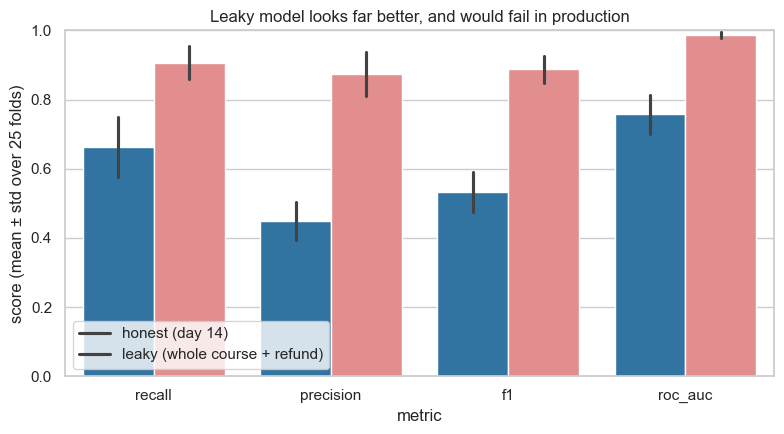

In [4]:
folds = per_fold(oof, 0.5)
leak = folds[folds["experiment"].isin(["logreg", "logreg_leaky"])]
leak = leak.melt(id_vars="experiment", value_vars=["recall", "precision", "f1", "roc_auc"], var_name="metric")

plt.figure(figsize=(8, 4.5))
sns.barplot(data=leak, x="metric", y="value", hue="experiment", errorbar="sd",
            palette={"logreg": "tab:blue", "logreg_leaky": "lightcoral"})
plt.ylim(0, 1)
plt.title("Leaky model looks far better, and would fail in production")
plt.ylabel("score (mean ± std over 25 folds)")
plt.legend(title="", labels=["honest (day 14)", "leaky (whole course + refund)"])
plt.tight_layout()
plt.show()

The leaky model's score is not real. On day 14 nobody has asked for a refund yet, and "days active over the whole course"
doesn't exist yet. **We report the honest model's numbers.** The gap is the price of predicting early enough to act.

## 5. How stable are the scores?

Each dot is one of the 25 test folds. A wide spread means a single 80/20 split could give quite a different answer.

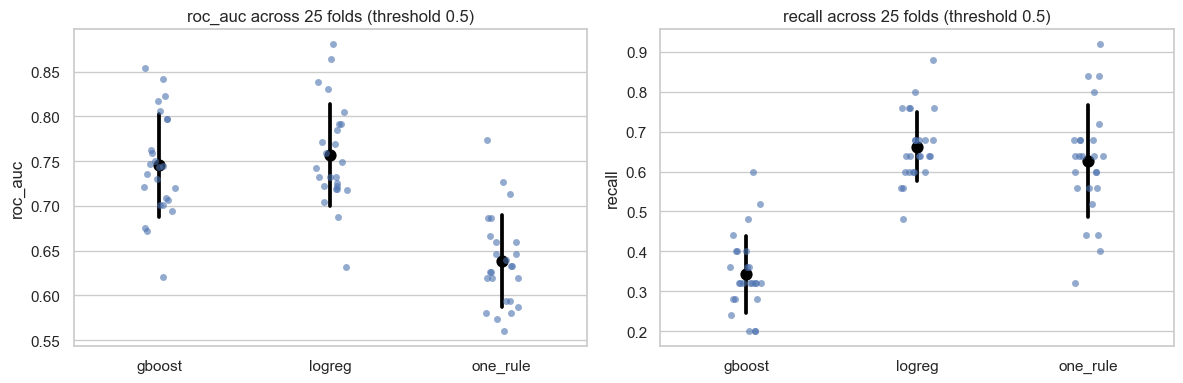

roc_auc       recall          f1      
               min   max    min   max   min   max
experiment                                       
gboost        0.62  0.85   0.20  0.60  0.29  0.70
logreg        0.63  0.88   0.48  0.88  0.44  0.65
one_rule      0.56  0.77   0.32  0.92  0.37  0.62

In [5]:
main = folds[folds["experiment"].isin(["one_rule", "logreg", "gboost"])]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, metric in zip(ax, ["roc_auc", "recall"]):
    sns.stripplot(data=main, x="experiment", y=metric, alpha=0.6, ax=a)
    sns.pointplot(data=main, x="experiment", y=metric, color="black", errorbar="sd", linestyle="none", ax=a)
    a.set(title=f"{metric} across 25 folds (threshold 0.5)", xlabel="")
plt.tight_layout()
plt.show()

main.groupby("experiment")[["roc_auc", "recall", "f1"]].agg(["min", "max"]).round(2)

Recall for the same model swings by roughly ±0.1 between folds. That's why one 80/20 split isn't enough evidence,
and why we report mean ± std.

## 6. Precision–recall curves (threshold-free comparison)

Each curve shows every possible trade-off for one model. Higher and further right is better.
We use repeat 0, so every student appears exactly once.

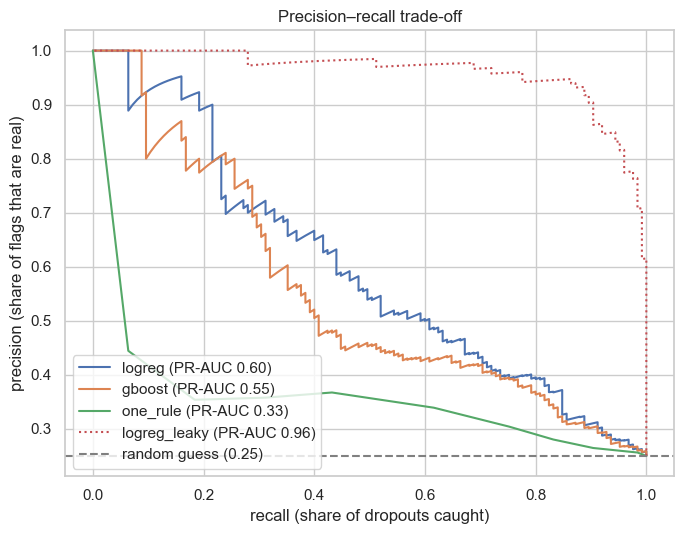

In [6]:
rep0 = oof[oof["repeat"] == 0]
base_rate = rep0.loc[rep0["experiment"] == "logreg", "y_true"].mean()

plt.figure(figsize=(7, 5.5))
for name in ["logreg", "gboost", "one_rule", "logreg_leaky"]:
    d = rep0[rep0["experiment"] == name]
    prec, rec, _ = precision_recall_curve(d["y_true"], d["proba"])
    style = ":" if name == "logreg_leaky" else "-"
    plt.plot(rec, prec, style, label=f"{name} (PR-AUC {average_precision_score(d['y_true'], d['proba']):.2f})")
plt.axhline(base_rate, color="grey", ls="--", label=f"random guess ({base_rate:.2f})")
plt.xlabel("recall (share of dropouts caught)")
plt.ylabel("precision (share of flags that are real)")
plt.title("Precision–recall trade-off")
plt.legend()
plt.tight_layout()
plt.show()

On curves, `gboost` and `logreg` are close. With 500 rows the extra complexity buys nothing,
so we prefer **logistic regression**: simpler, and its coefficients explain *why* a student was flagged.

## 7. Choosing the threshold

0.5 is just a default. We pick the cut-off from the business goal: **catch at least 80% of dropouts**, using the
highest threshold that does so (to keep false alarms down).

In [7]:
TARGET_RECALL = 0.80

lr = oof[oof["experiment"] == "logreg"]
sweep = pd.DataFrame([
    per_fold(lr, t)[["recall", "precision", "f1", "flagged_%"]].mean().rename(round(t, 2))
    for t in np.arange(0.15, 0.76, 0.05)
])
sweep.index.name = "threshold"

ok = sweep[sweep["recall"] >= TARGET_RECALL]
THRESHOLD = ok.index.max()
print(f"Chosen threshold: {THRESHOLD}  (highest with mean recall >= {TARGET_RECALL})")
sweep.round(2)

Chosen threshold: 0.35  (highest with mean recall >= 0.8)


,recall,precision,f1,flagged_%
threshold,,,,
0.15,0.95,0.27,0.42,87.36
0.20,0.91,0.29,0.44,78.96
0.25,0.87,0.31,0.46,70.20
0.30,0.84,0.34,0.48,62.00
0.35,0.81,0.37,0.51,54.96
0.40,0.77,0.40,0.52,48.44
0.45,0.71,0.42,0.53,42.40
0.50,0.66,0.45,0.53,37.12
0.55,0.62,0.48,0.54,32.16


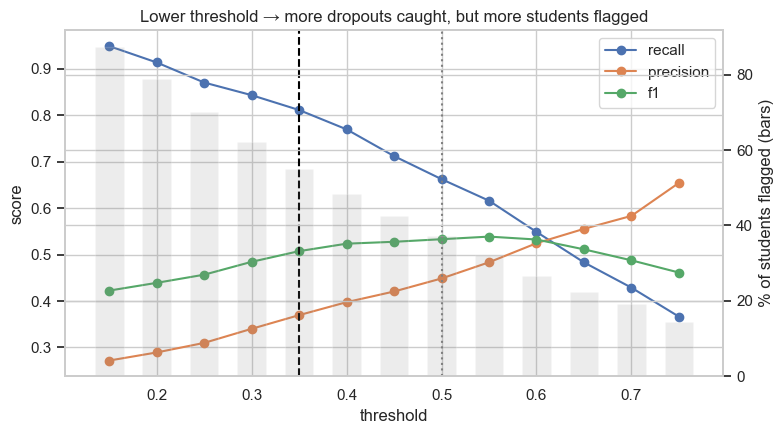

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sweep[["recall", "precision", "f1"]].plot(ax=ax, marker="o")
ax2 = ax.twinx()
ax2.bar(sweep.index, sweep["flagged_%"], width=0.03, alpha=0.15, color="grey")
ax2.set_ylabel("% of students flagged (bars)")
ax.axvline(THRESHOLD, color="black", ls="--")
ax.axvline(0.5, color="grey", ls=":")
ax.set(xlabel="threshold", ylabel="score", title="Lower threshold → more dropouts caught, but more students flagged")
plt.tight_layout()
plt.show()

**Caveat:** we chose the threshold on the same cross-validated predictions we report, which is slightly optimistic.
With more data, we'd choose it on a separate validation split.

## 8. What this means for the tutor team

At the chosen threshold, scaled to a cohort of 1,000 students (250 of whom will drop out):

In [9]:
def tutor_view(oof_one_model, threshold, cohort=1000):
    rep = oof_one_model[oof_one_model["repeat"] == 0]
    tn, fp, fn, tp = confusion_matrix(rep["y_true"], rep["proba"] >= threshold).ravel()
    scale = cohort / len(rep)
    return pd.Series({
        "students flagged":           round((tp + fp) * scale),
        "  of whom really at risk":   round(tp * scale),
        "  false alarms":             round(fp * scale),
        "dropouts missed":            round(fn * scale),
        "flags that are real (%)":    round(100 * tp / (tp + fp)),
    }, name=f"threshold {threshold}")

pd.concat([tutor_view(lr, 0.5), tutor_view(lr, THRESHOLD)], axis=1)

,threshold 0.5,threshold 0.35
students flagged,376,542
of whom really at risk,168,206
false alarms,208,336
dropouts missed,82,44
flags that are real (%),45,38


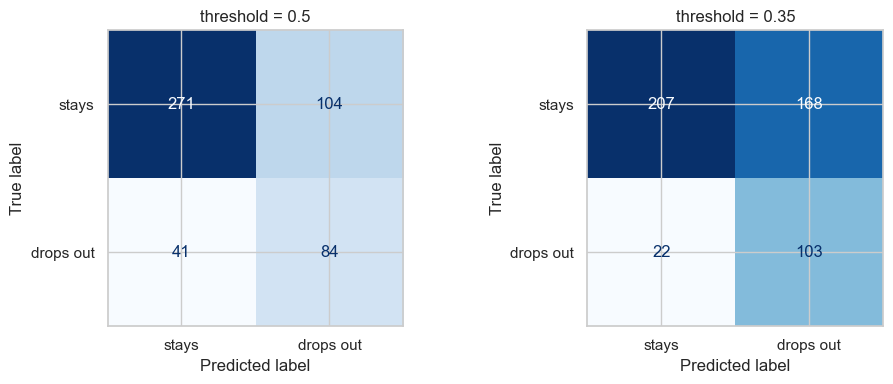

In [10]:
rep0_lr = lr[lr["repeat"] == 0]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, t in zip(ax, [0.5, THRESHOLD]):
    ConfusionMatrixDisplay.from_predictions(rep0_lr["y_true"], rep0_lr["proba"] >= t,
                                            display_labels=["stays", "drops out"], cmap="Blues", ax=a, colorbar=False)
    a.set_title(f"threshold = {t}")
plt.tight_layout()
plt.show()

**The honest trade-off:** to catch 80% of dropouts on day 14, we flag about half the cohort, and roughly
2 in 3 flags are false alarms. That's fine for a **cheap, automatic nudge** (an email, a hint, a reminder),
but too many for one-to-one tutor calls.

A sensible plan is **two tiers**: everyone above the low threshold gets an automated nudge, and only the top-scoring
students (e.g. above 0.6) go to a human tutor.

### Try it yourself

Change `MY_THRESHOLD` and re-run this cell. No retraining needed.

In [11]:
MY_THRESHOLD = 0.3
summary(oof[oof["experiment"].isin(["logreg", "gboost"])], threshold=MY_THRESHOLD)

,recall,precision,f1,accuracy,roc_auc,pr_auc,flagged_%
experiment,,,,,,,
logreg,0.84 ± 0.08,0.34 ± 0.03,0.48 ± 0.04,0.55 ± 0.04,0.76 ± 0.06,0.60 ± 0.07,62.00 ± 3.95
gboost,0.55 ± 0.10,0.49 ± 0.08,0.51 ± 0.08,0.74 ± 0.04,0.75 ± 0.06,0.57 ± 0.08,28.40 ± 3.73


## 9. Fairness check: country

Two questions:
1. Does the model **need** country? (Compare `logreg` and `logreg_no_country`.)
2. Does it catch dropouts **equally well** in every country?

In [12]:
summary(oof[oof["experiment"].isin(["logreg", "logreg_no_country"])], threshold=THRESHOLD)

,recall,precision,f1,accuracy,roc_auc,pr_auc,flagged_%
experiment,,,,,,,
logreg,0.81 ± 0.08,0.37 ± 0.03,0.51 ± 0.05,0.61 ± 0.04,0.76 ± 0.06,0.60 ± 0.07,54.96 ± 3.65
logreg_no_country,0.82 ± 0.08,0.37 ± 0.03,0.51 ± 0.04,0.60 ± 0.04,0.77 ± 0.06,0.61 ± 0.07,55.44 ± 3.71


In [13]:
countries = pd.read_csv(ROOT / "data" / "features" / "features_early.csv", usecols=["student_id", "country"])
by_country = lr.merge(countries, on="student_id")
by_country["flagged"] = by_country["proba"] >= THRESHOLD

per_country = by_country.groupby("country").apply(
    lambda g: pd.Series({
        "students": g["student_id"].nunique(),
        "dropouts": g.loc[g["y_true"] == 1, "student_id"].nunique(),
        "recall": g.loc[g["y_true"] == 1, "flagged"].mean(),
        "flagged_%": 100 * g["flagged"].mean(),
    }), include_groups=False)
per_country.round(2)

,students,dropouts,recall,flagged_%
country,,,,
Bangladesh,48.0,14.0,0.91,53.33
India,303.0,74.0,0.82,54.92
Kenya,35.0,6.0,0.50,42.86
Sri Lanka,50.0,12.0,0.77,52.00
UAE,64.0,19.0,0.81,65.31


- Removing `country` doesn't hurt (it's slightly better, if anything), so **we drop it from the final model**.
  There's no reason to carry a fairness risk that adds no accuracy.
- Recall varies by country, but some countries have only a handful of dropouts, so those differences are mostly noise.
  It's still worth monitoring once real data arrives.

## 10. Why does the model flag a student?

Coefficients from the final logistic regression (trained on all 500 students, **without country**, per Section 9).
Features are standardised, so bigger bars = stronger effect. **Odds ratio > 1** = raises dropout risk.

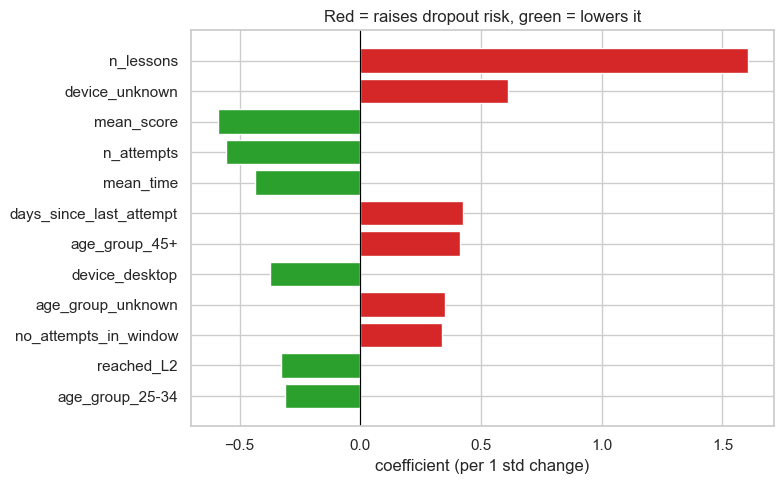

,feature,coefficient,odds_ratio
0,n_lessons,1.60,4.97
1,device_unknown,0.61,1.85
2,mean_score,-0.59,0.55
3,n_attempts,-0.56,0.57
4,mean_time,-0.44,0.65
5,days_since_last_attempt,0.43,1.53
6,age_group_45+,0.41,1.51
7,device_desktop,-0.37,0.69
8,age_group_unknown,0.35,1.42
9,no_attempts_in_window,0.34,1.40


In [14]:
top = coefs.head(12).iloc[::-1]
colors = ["tab:red" if c > 0 else "tab:green" for c in top["coefficient"]]
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["coefficient"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.title("Red = raises dropout risk, green = lowers it")
plt.xlabel("coefficient (per 1 std change)")
plt.tight_layout()
plt.show()

coefs.head(12).round(2)

**In plain language:**

- **Trying many lessons quickly** (`n_lessons` ↑) raises risk. Read together with `n_attempts` (↓ risk): *holding the number of
  quizzes fixed*, covering more lessons means **fewer retries**. Students who rush ahead without retrying are the ones who quit.
  (These two features are correlated, so read them as a pair, not one by one.)
- **Lower scores** and **less time per quiz** raise risk. Struggling and rushing are the warning signs.
- **Unknown device** raises risk. Keeping missingness as its own category paid off.
- **A longer gap since the last attempt** (as of day 14) raises risk. Going quiet is a warning sign.

## Summary

| Question | Answer |
|---|---|
| Best honest model | Logistic regression on day-14 features, ROC-AUC ≈ 0.75 |
| Better than baselines? | Yes: well above majority (0.50) and the one-rule baseline (≈0.64) |
| Worth using gradient boosting? | No: same ranking quality, harder to explain |
| Threshold | Chosen for recall ≥ 0.80 (see Section 7), not the default 0.5 |
| Cost of that recall | About half of students flagged, ~38% of flags real → suits automated nudges, not tutor calls |
| Leak check | With `refund_requested` + whole-course data: AUC ≈ 0.98. Not achievable in production |
| Country | Not needed → drop it |

**Weakest part:** with only 125 dropouts, every number here carries roughly ±0.1 uncertainty, and ~40% of dropouts
had already gone quiet before day 14. An earlier window (day 7) or real dropout dates would be the next things to try.